### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['figure.dpi'] = 100

### Data

In [2]:
df = pd.read_csv('KRI_GCTS_Dataset.csv', low_memory=False)
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')

Dataset shape: 8,026 rows × 221 columns


---
## Section 1: Data Cleaning & Preparation
Map categorical salary bins to numeric midpoints so we can compute means and progressions.

In [3]:
# --- Salary bin → midpoint mappings ---

salary_cj_map = {
    'Below RM 1,500': 1250,
    'RM 1,500 - RM 2,000': 1750,
    'RM 2,001 - RM 3,000': 2500,
    'RM 3,001 - RM 4,000': 3500,
    'RM 4,001 - RM 5,000': 4500,
    'RM 5,001 - RM 6,000': 5500,
    'RM 6,001 - RM 7,000': 6500,
    'RM 7,001 - RM 8,000': 7500,
    'RM 8,001 - RM 9,000': 8500,
    'RM 9,001 - RM 10,000': 9500,
    'RM 10,001 - RM 11,000': 10500,
    'RM 11,001 - RM 12,000': 11500,
    'RM 12,001 - RM 13,000': 12500,
    'RM 13,001 - RM 14,000': 13500,
    'RM 14,001 - RM 15,000': 14500,
    'Above RM 15,000': 17500,
}

salary_fj_map = {
    'RM 1,000 and below': 750,
    'RM 1,001 - RM 2,000': 1500,
    'RM 2,001 - RM 3,000': 2500,
    'RM 3,001 - RM 4,000': 3500,
    'RM 4,001 - RM 5,000': 4500,
    'RM 5,001 - RM 10,000': 7500,
    'Above RM 10,000': 12500,
}

# income_se uses the same bins as salary_cj
income_se_map = salary_cj_map.copy()

# Apply mappings (99.0 → NaN automatically since it's not in the map)
df['salary_cj_mid'] = df['salary_cj'].map(salary_cj_map)
df['salary_fj_mid'] = df['salary_fj'].map(salary_fj_map)
df['income_se_mid'] = df['income_se'].map(income_se_map)

# Wage progression (only for respondents with both values)
df['salary_progression'] = df['salary_cj_mid'] - df['salary_fj_mid']
df['salary_growth_pct'] = (df['salary_progression'] / df['salary_fj_mid']) * 100

print('Numeric salary columns created:')
print(f"  salary_cj_mid : {df['salary_cj_mid'].notna().sum():,} valid values")
print(f"  salary_fj_mid : {df['salary_fj_mid'].notna().sum():,} valid values")
print(f"  income_se_mid : {df['income_se_mid'].notna().sum():,} valid values")
print(f"  salary_progression : {df['salary_progression'].notna().sum():,} valid values (have both first & current)")

Numeric salary columns created:
  salary_cj_mid : 4,818 valid values
  salary_fj_mid : 4,493 valid values
  income_se_mid : 509 valid values
  salary_progression : 2,304 valid values (have both first & current)


In [4]:
# --- Short labels for FieldofStudy (excluding unknown study fields) ---

# Exclude unknown / unclassified study fields
df = df[df['FieldofStudy'] != 'Field unknown'].copy()

field_short = {
    'Engineering, manufacturing and construction': 'Engineering',
    'Business, administration and law': 'Business & Law',
    'Natural sciences, mathematics and statistics': 'Natural Sciences',
    'Arts & humanities': 'Arts & Humanities',
    'Health and welfare': 'Health & Welfare',
    'Education': 'Education',
    'Information and communication technologies': 'ICT',
    'Services': 'Services',
    'Social sci, journalism &': 'Social Sci & Journalism',
    'Agriculture, forestry, fisheries and veterinary': 'Agriculture',
    'General programmes': 'General',
}

df['Field'] = df['FieldofStudy'].map(field_short)

# Verify mapping
unmapped = df[df['Field'].isna()]['FieldofStudy'].unique()
if len(unmapped) > 0:
    print(f'WARNING: Unmapped FieldofStudy values: {unmapped}')
else:
    print(f'Successfully mapped {df["Field"].nunique()} study fields (excluding "Field unknown", n={len(df):,} remaining):')
    print(df['Field'].value_counts())

Successfully mapped 11 study fields (excluding "Field unknown", n=7,984 remaining):
Field
Engineering                1745
Business & Law             1520
Natural Sciences           1053
Arts & Humanities           817
Health & Welfare            701
Education                   496
ICT                         493
Services                    485
Social Sci & Journalism     394
Agriculture                 235
General                      45
Name: count, dtype: int64


---
## Section 2: Dataset Overview & Salary Distribution

In [5]:
# --- 2a. Missing value summary for key salary columns ---

salary_cols = ['salary_cj', 'salary_fj', 'income_se', 'salary_cj_mid', 'salary_fj_mid', 'income_se_mid']
missing_df = pd.DataFrame({
    'Column': salary_cols,
    'Total': [len(df)] * len(salary_cols),
    'Valid (non-99/non-NaN)': [df[c].notna().sum() if c.endswith('_mid') else (df[c] != '99.0').sum() for c in salary_cols],
})
missing_df['Missing'] = missing_df['Total'] - missing_df['Valid (non-99/non-NaN)']
missing_df['% Missing'] = (missing_df['Missing'] / missing_df['Total'] * 100).round(1)
missing_df

,Column,Total,Valid (non-99/non-NaN),Missing,% Missing
0,salary_cj,7984,4800,3184,39.9
1,salary_fj,7984,4467,3517,44.1
2,income_se,7984,505,7479,93.7
3,salary_cj_mid,7984,4800,3184,39.9
4,salary_fj_mid,7984,4467,3517,44.1
5,income_se_mid,7984,505,7479,93.7


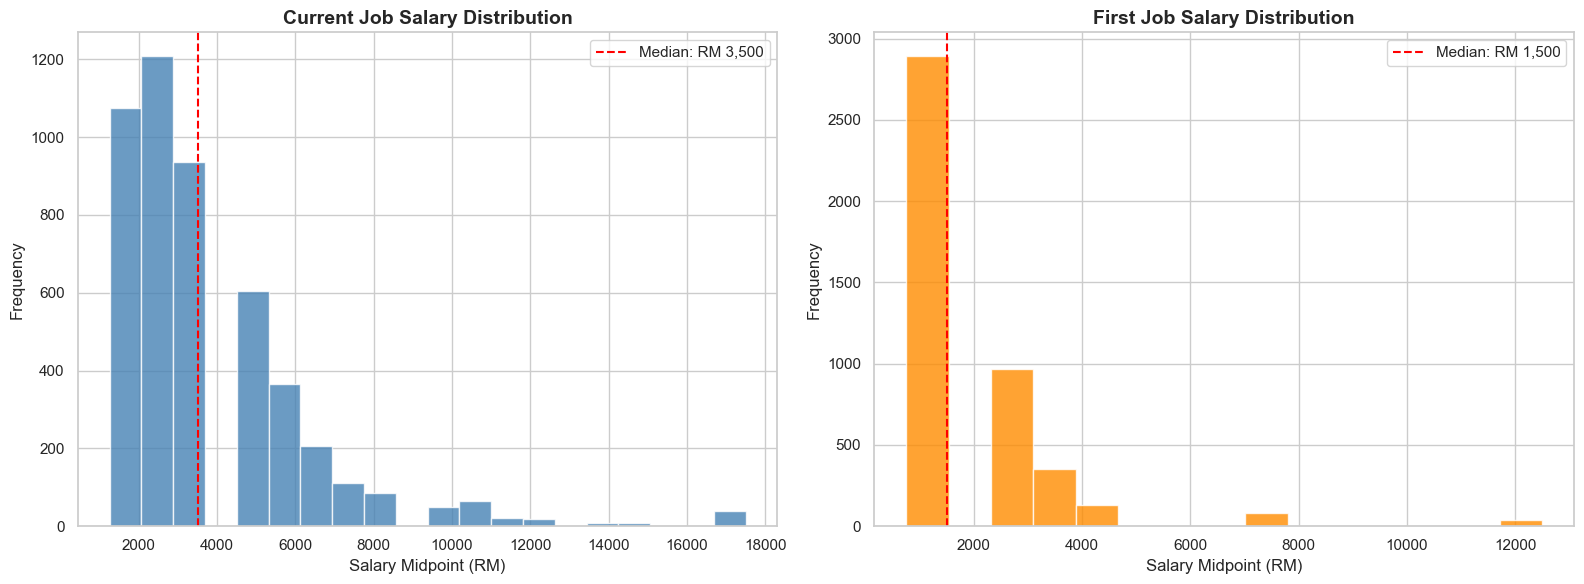

In [6]:
# --- 2b. Overall salary distributions ---

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Current job salary distribution
df['salary_cj_mid'].dropna().hist(bins=20, ax=axes[0], color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_title('Current Job Salary Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Salary Midpoint (RM)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].axvline(df['salary_cj_mid'].median(), color='red', linestyle='--', linewidth=1.5, label=f"Median: RM {df['salary_cj_mid'].median():,.0f}")
axes[0].legend(fontsize=11)

# First job salary distribution
df['salary_fj_mid'].dropna().hist(bins=15, ax=axes[1], color='darkorange', edgecolor='white', alpha=0.8)
axes[1].set_title('First Job Salary Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Salary Midpoint (RM)', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].axvline(df['salary_fj_mid'].median(), color='red', linestyle='--', linewidth=1.5, label=f"Median: RM {df['salary_fj_mid'].median():,.0f}")
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

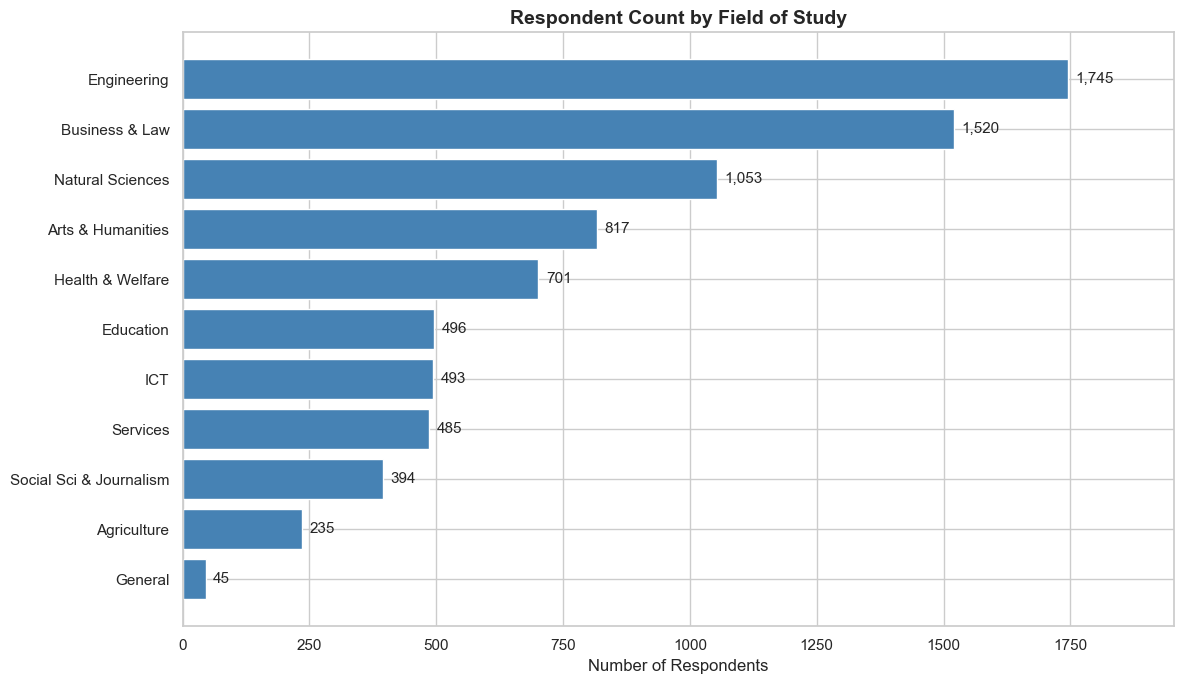

In [7]:
# --- 2c. Respondent count by FieldofStudy ---

field_counts = df['Field'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(field_counts.index, field_counts.values, color='steelblue', edgecolor='white')
ax.set_xlabel('Number of Respondents', fontsize=12)
ax.set_title('Respondent Count by Field of Study', fontsize=14, fontweight='bold')

# Annotate bars with counts
for bar, count in zip(bars, field_counts.values):
    ax.text(bar.get_width() + 15, bar.get_y() + bar.get_height()/2,
            f'{count:,}', va='center', fontsize=11)

ax.set_xlim(0, field_counts.max() * 1.12)
plt.tight_layout()
plt.show()

---
## Section 3: Average Wage by Study Field (Cross-Sectional)

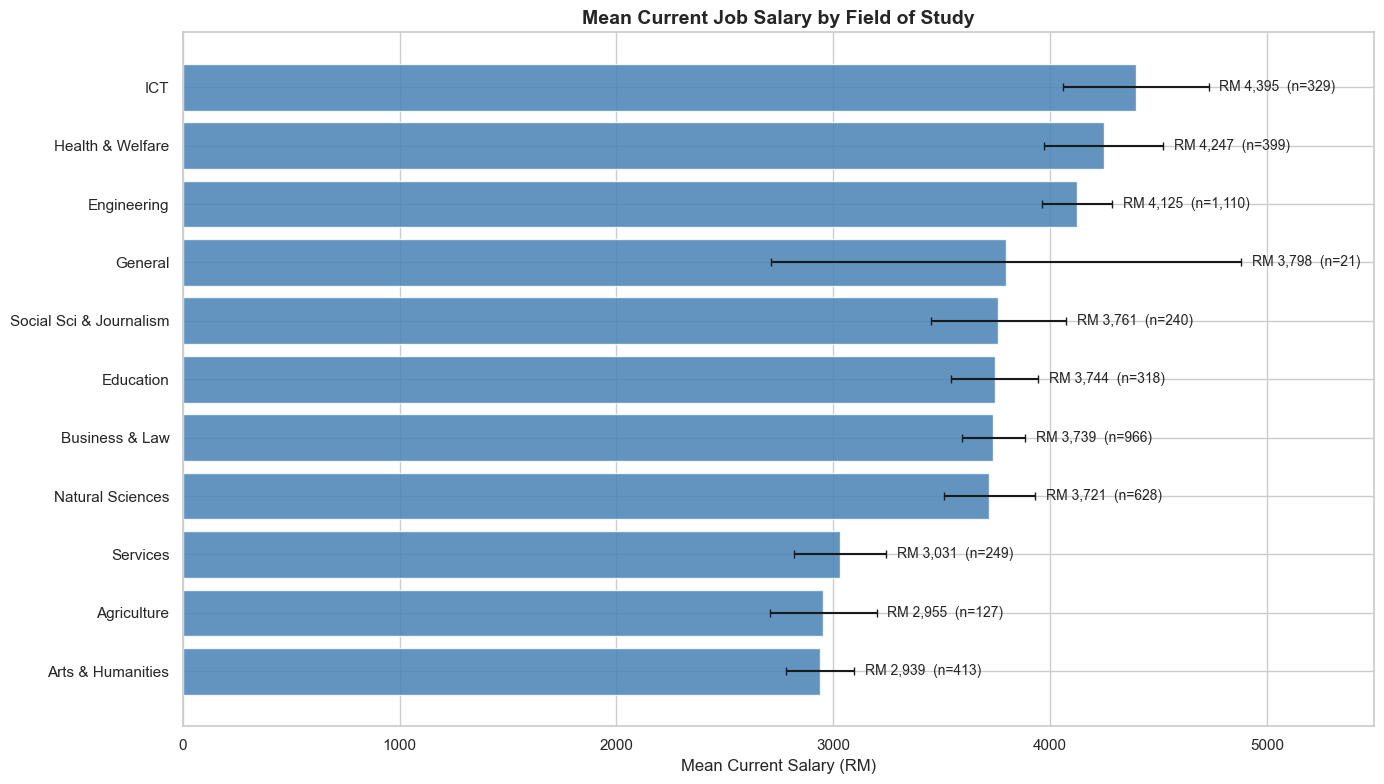

In [8]:
# --- 3a. Mean Current Salary by FieldofStudy ---

cj_stats = df.groupby('Field')['salary_cj_mid'].agg(['mean', 'median', 'std', 'count']).sort_values('mean', ascending=True)
cj_stats['se'] = cj_stats['std'] / np.sqrt(cj_stats['count'])
cj_stats['ci95'] = 1.96 * cj_stats['se']

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(cj_stats.index, cj_stats['mean'], xerr=cj_stats['ci95'],
               color='steelblue', edgecolor='white', capsize=3, alpha=0.85)
ax.set_xlabel('Mean Current Salary (RM)', fontsize=12)
ax.set_title('Mean Current Job Salary by Field of Study', fontsize=14, fontweight='bold')

# Annotate with mean & n
for i, (field, row) in enumerate(cj_stats.iterrows()):
    ax.text(row['mean'] + row['ci95'] + 50, i,
            f"RM {row['mean']:,.0f}  (n={row['count']:,.0f})",
            va='center', fontsize=10)

ax.set_xlim(0, cj_stats['mean'].max() * 1.25)
plt.tight_layout()
plt.show()

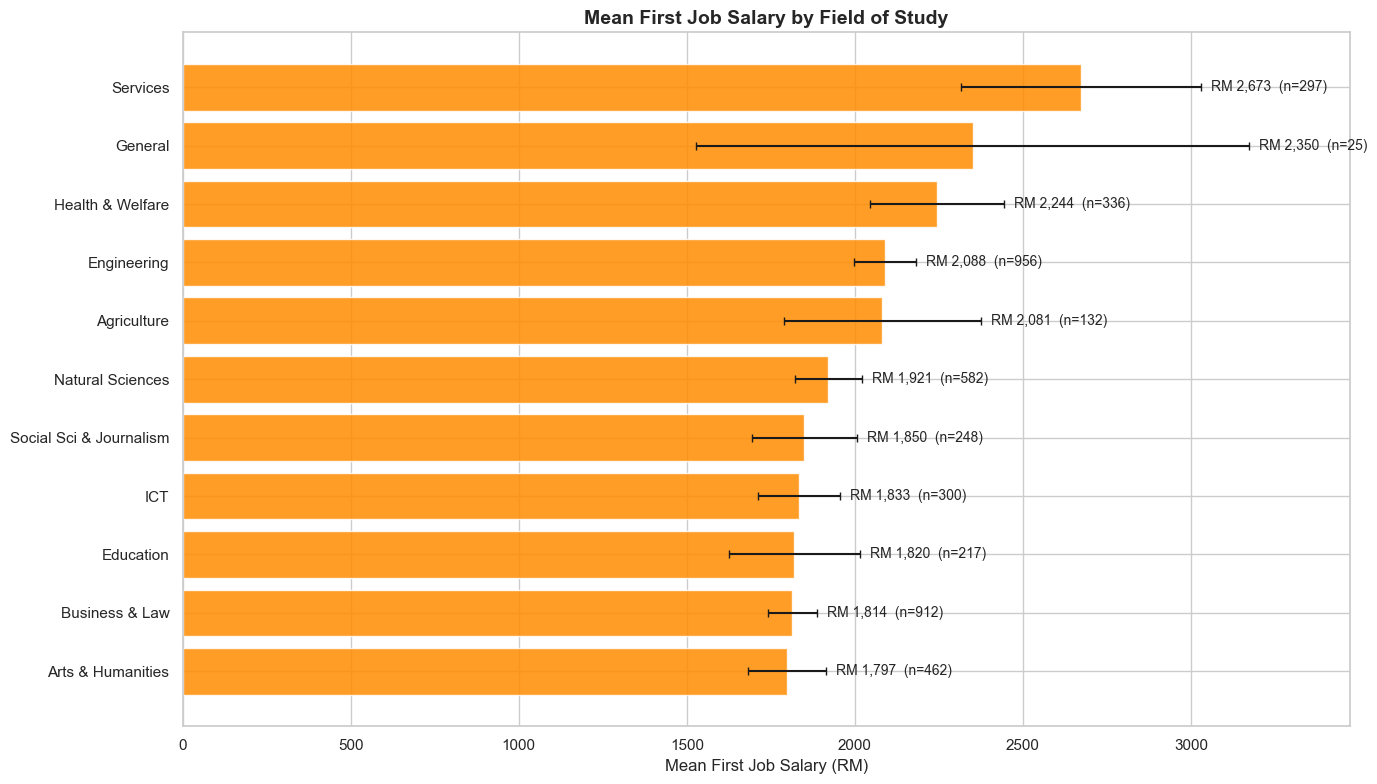

In [9]:
# --- 3b. Mean First Job Salary by FieldofStudy ---

fj_stats = df.groupby('Field')['salary_fj_mid'].agg(['mean', 'median', 'std', 'count']).sort_values('mean', ascending=True)
fj_stats['se'] = fj_stats['std'] / np.sqrt(fj_stats['count'])
fj_stats['ci95'] = 1.96 * fj_stats['se']

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(fj_stats.index, fj_stats['mean'], xerr=fj_stats['ci95'],
               color='darkorange', edgecolor='white', capsize=3, alpha=0.85)
ax.set_xlabel('Mean First Job Salary (RM)', fontsize=12)
ax.set_title('Mean First Job Salary by Field of Study', fontsize=14, fontweight='bold')

for i, (field, row) in enumerate(fj_stats.iterrows()):
    ax.text(row['mean'] + row['ci95'] + 30, i,
            f"RM {row['mean']:,.0f}  (n={row['count']:,.0f})",
            va='center', fontsize=10)

ax.set_xlim(0, fj_stats['mean'].max() * 1.3)
plt.tight_layout()
plt.show()

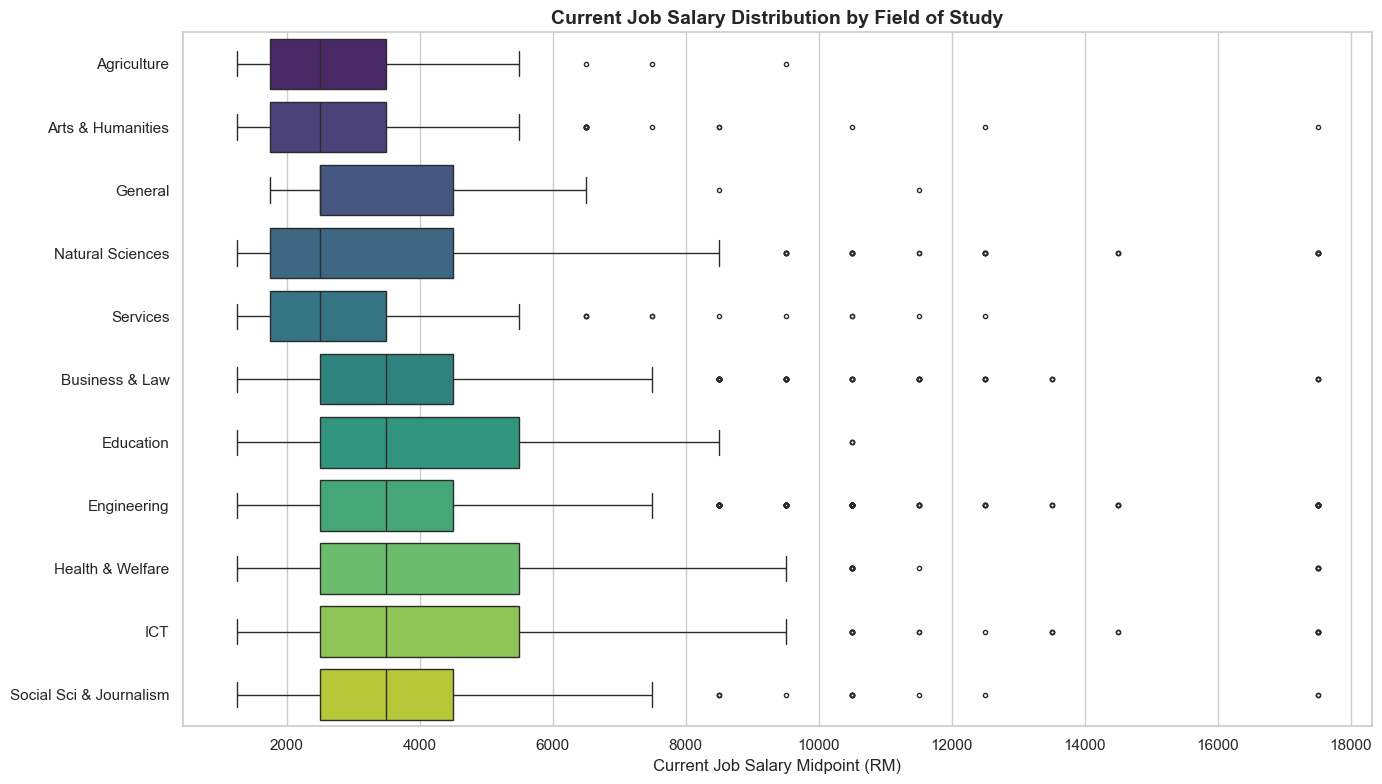

In [10]:
# --- 3c. Box plot: Current salary distribution by FieldofStudy ---

# Order fields by median salary
field_order = df.groupby('Field')['salary_cj_mid'].median().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(14, 8))
sns.boxplot(data=df.dropna(subset=['salary_cj_mid']), y='Field', x='salary_cj_mid',
            order=field_order, palette='viridis', ax=ax, fliersize=3)
ax.set_xlabel('Current Job Salary Midpoint (RM)', fontsize=12)
ax.set_ylabel('')
ax.set_title('Current Job Salary Distribution by Field of Study', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [11]:
# --- 3d. Summary statistics table ---

summary = df.groupby('Field').agg(
    cj_mean=('salary_cj_mid', 'mean'),
    cj_median=('salary_cj_mid', 'median'),
    cj_std=('salary_cj_mid', 'std'),
    cj_n=('salary_cj_mid', 'count'),
    fj_mean=('salary_fj_mid', 'mean'),
    fj_median=('salary_fj_mid', 'median'),
    fj_std=('salary_fj_mid', 'std'),
    fj_n=('salary_fj_mid', 'count'),
).round(0)

summary.columns = pd.MultiIndex.from_tuples([
    ('Current Job Salary', 'Mean (RM)'),
    ('Current Job Salary', 'Median (RM)'),
    ('Current Job Salary', 'Std Dev'),
    ('Current Job Salary', 'n'),
    ('First Job Salary', 'Mean (RM)'),
    ('First Job Salary', 'Median (RM)'),
    ('First Job Salary', 'Std Dev'),
    ('First Job Salary', 'n'),
])

summary.sort_values(('Current Job Salary', 'Mean (RM)'), ascending=False)

Current Job Salary                            \
                                 Mean (RM) Median (RM) Std Dev     n   
Field                                                                  
ICT                                 4395.0      3500.0  3110.0   329   
Health & Welfare                    4247.0      3500.0  2787.0   399   
Engineering                         4125.0      3500.0  2752.0  1110   
General                             3798.0      2500.0  2534.0    21   
Social Sci & Journalism             3761.0      3500.0  2455.0   240   
Education                           3744.0      3500.0  1829.0   318   
Business & Law                      3739.0      3500.0  2286.0   966   
Natural Sciences                    3721.0      2500.0  2675.0   628   
Services                            3031.0      2500.0  1700.0   249   
Agriculture                         2955.0      2500.0  1411.0   127   
Arts & Humanities                   2939.0      2500.0  1631.0   413   

                        First Job Salary                           
                               Mean (RM) Median (RM) Std Dev    n  
Field                                                              
ICT                               1833.0      1500.0  1086.0  300  
Health & Welfare                  2244.0      1500.0  1870.0  336  
Engineering                       2088.0      1500.0  1455.0  956  
General                           2350.0      1500.0  2099.0   25  
Social Sci & Journalism           1850.0      1500.0  1264.0  248  
Education                         1820.0      1500.0  1458.0  217  
Business & Law                    1814.0      1500.0  1110.0  912  
Natural Sciences                  1921.0      1500.0  1233.0  582  
Services                          2673.0      1500.0  3131.0  297  
Agriculture                       2081.0      1500.0  1719.0  132  
Arts & Humanities                 1797.0      1500.0  1275.0  462

---
## Section 4: Wage Progression — First Job → Current Job
This is the core analysis: how much do salaries grow from first job to current job, and how does this differ by field of study?

> **Outlier handling:** Paired records where current salary is below first salary are excluded as salary-inversion outliers (reporting inconsistencies). General Programmes is excluded from ranked comparisons because it has too few paired observations for a reliable category mean. Cross-sectional salary summaries in Sections 2–3 retain all valid responses.


Respondents with both first & current job salary: 2,296

Excluded salary-inversion outliers: 180 (7.8% of paired respondents)
Field
Engineering                38
Natural Sciences           37
Business & Law             31
Arts & Humanities          20
Agriculture                12
Health & Welfare           10
Social Sci & Journalism    10
Education                   8
Services                    7
ICT                         4
General                     3

General Programmes paired observations after cleaning: 4 (excluded from rankings)
Final ranked paired sample: 2,112 across 10 disciplines


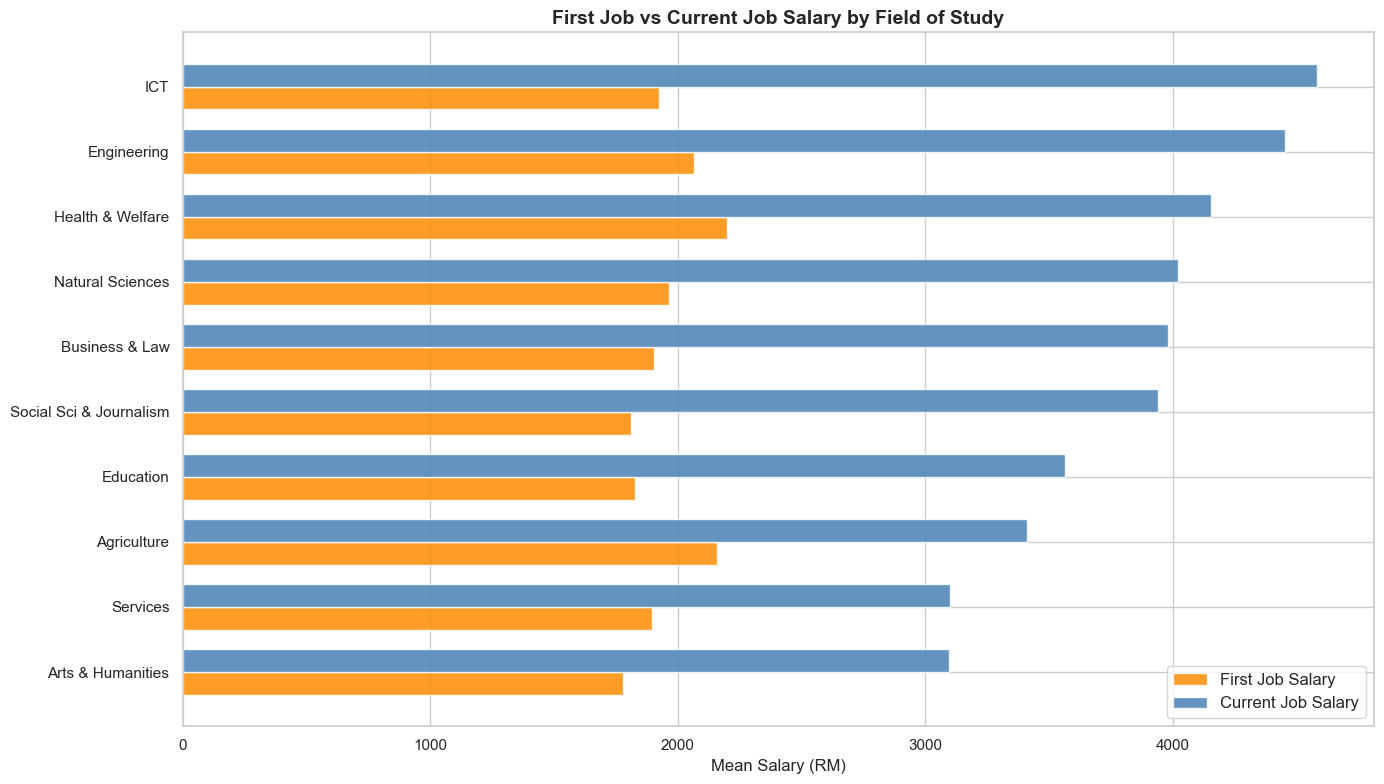

In [12]:
# --- 4a. Grouped bar: First Job vs Current Job salary by field ---

# Only use respondents who have both first and current salary
df_prog_raw = df.dropna(subset=['salary_cj_mid', 'salary_fj_mid']).copy()
print(f'Respondents with both first & current job salary: {len(df_prog_raw):,}')

# Outlier handling: current salary below first salary is treated as a reporting
# inconsistency rather than a genuine wage trajectory.
inversion_mask = df_prog_raw['salary_progression'] < 0
inversion_audit = (
    df_prog_raw[inversion_mask]
    .groupby('Field')
    .size()
    .sort_values(ascending=False)
)
print(f'\nExcluded salary-inversion outliers: {inversion_mask.sum():,} '
      f'({inversion_mask.mean():.1%} of paired respondents)')
print(inversion_audit.to_string())

df_prog = df_prog_raw[~inversion_mask].copy()

# General Programmes has too few paired observations for a reliable category mean.
general_paired = (df_prog['Field'] == 'General').sum()
df_prog = df_prog[df_prog['Field'] != 'General'].copy()
print(f'\nGeneral Programmes paired observations after cleaning: {general_paired} (excluded from rankings)')
print(f'Final ranked paired sample: {len(df_prog):,} across {df_prog["Field"].nunique()} disciplines')

prog_means = df_prog.groupby('Field')[['salary_fj_mid', 'salary_cj_mid']].mean().sort_values('salary_cj_mid')

fig, ax = plt.subplots(figsize=(14, 8))
y = np.arange(len(prog_means))
height = 0.35

bars1 = ax.barh(y - height/2, prog_means['salary_fj_mid'], height, label='First Job Salary',
                color='darkorange', edgecolor='white', alpha=0.85)
bars2 = ax.barh(y + height/2, prog_means['salary_cj_mid'], height, label='Current Job Salary',
                color='steelblue', edgecolor='white', alpha=0.85)

ax.set_yticks(y)
ax.set_yticklabels(prog_means.index)
ax.set_xlabel('Mean Salary (RM)', fontsize=12)
ax.set_title('First Job vs Current Job Salary by Field of Study', fontsize=14, fontweight='bold')
ax.legend(fontsize=12, loc='lower right')
plt.tight_layout()
plt.show()


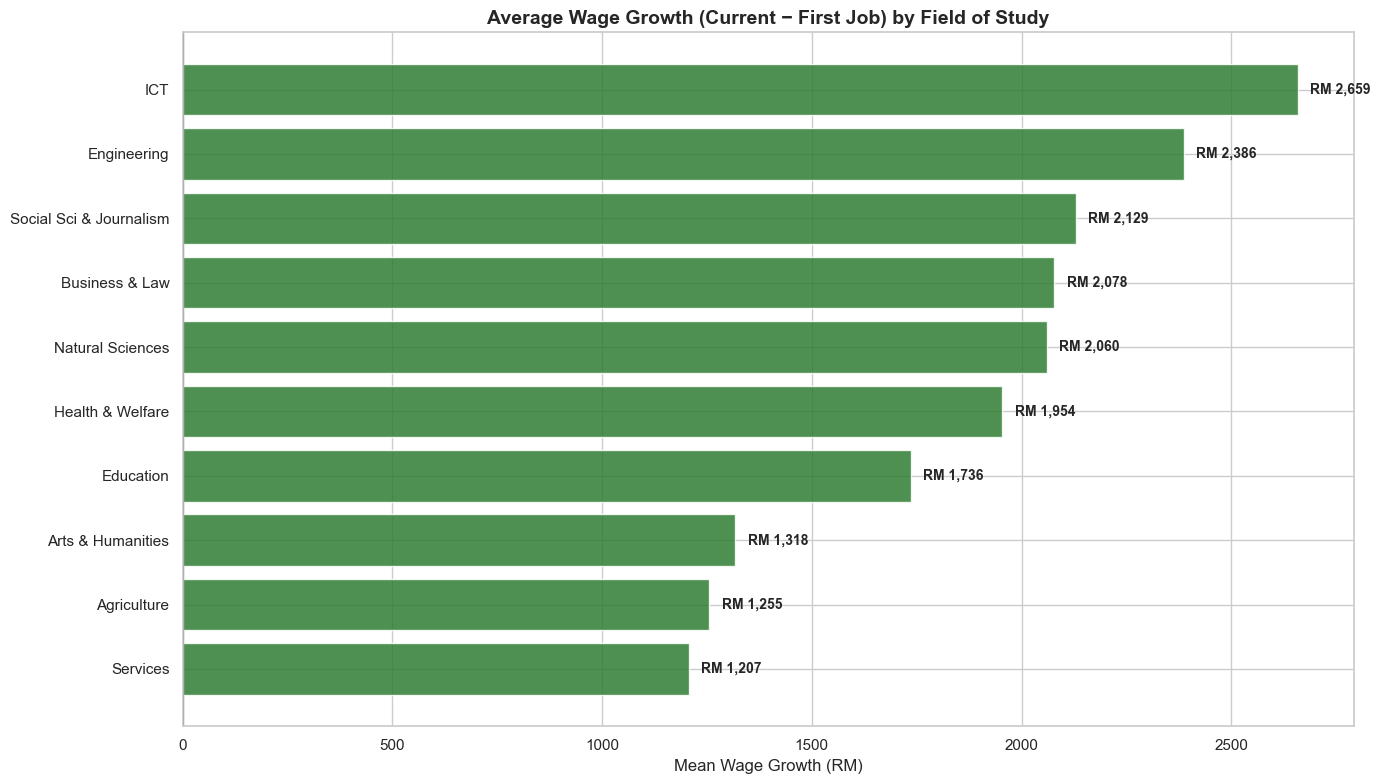

In [13]:
# --- 4b. Absolute Wage Growth (RM) by Field ---

growth = df_prog.groupby('Field')['salary_progression'].mean().sort_values()

fig, ax = plt.subplots(figsize=(14, 8))
colors = ['#d32f2f' if v < 0 else '#2e7d32' for v in growth.values]
bars = ax.barh(growth.index, growth.values, color=colors, edgecolor='white', alpha=0.85)
ax.set_xlabel('Mean Wage Growth (RM)', fontsize=12)
ax.set_title('Average Wage Growth (Current − First Job) by Field of Study', fontsize=14, fontweight='bold')
ax.axvline(0, color='black', linewidth=0.8)

for bar, val in zip(bars, growth.values):
    x_pos = val + 30 if val >= 0 else val - 30
    ha = 'left' if val >= 0 else 'right'
    ax.text(x_pos, bar.get_y() + bar.get_height()/2,
            f'RM {val:,.0f}', va='center', ha=ha, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

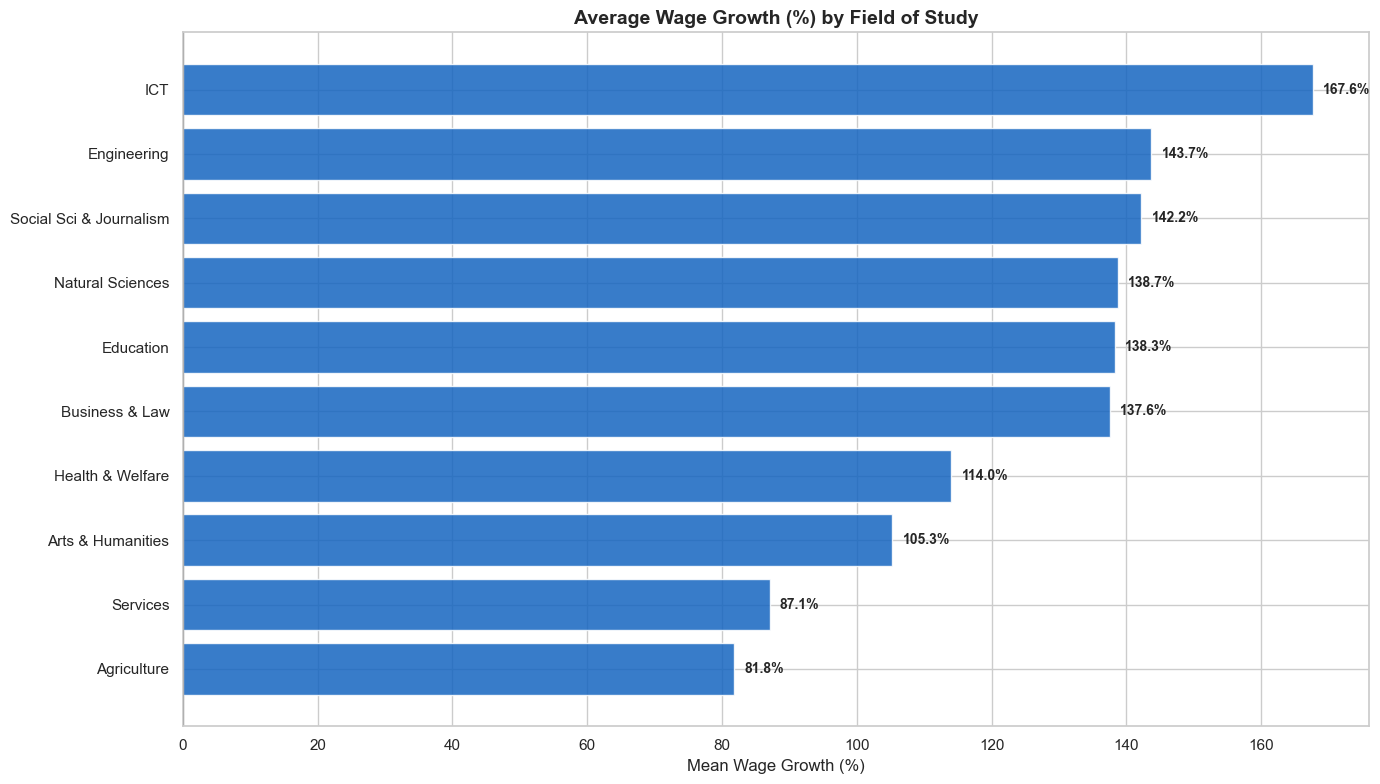

In [14]:
# --- 4c. Percentage Wage Growth by Field ---

pct_growth = df_prog.groupby('Field')['salary_growth_pct'].mean().sort_values()

fig, ax = plt.subplots(figsize=(14, 8))
colors = ['#d32f2f' if v < 0 else '#1565c0' for v in pct_growth.values]
bars = ax.barh(pct_growth.index, pct_growth.values, color=colors, edgecolor='white', alpha=0.85)
ax.set_xlabel('Mean Wage Growth (%)', fontsize=12)
ax.set_title('Average Wage Growth (%) by Field of Study', fontsize=14, fontweight='bold')
ax.axvline(0, color='black', linewidth=0.8)

for bar, val in zip(bars, pct_growth.values):
    x_pos = val + 1.5 if val >= 0 else val - 1.5
    ha = 'left' if val >= 0 else 'right'
    ax.text(x_pos, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', ha=ha, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

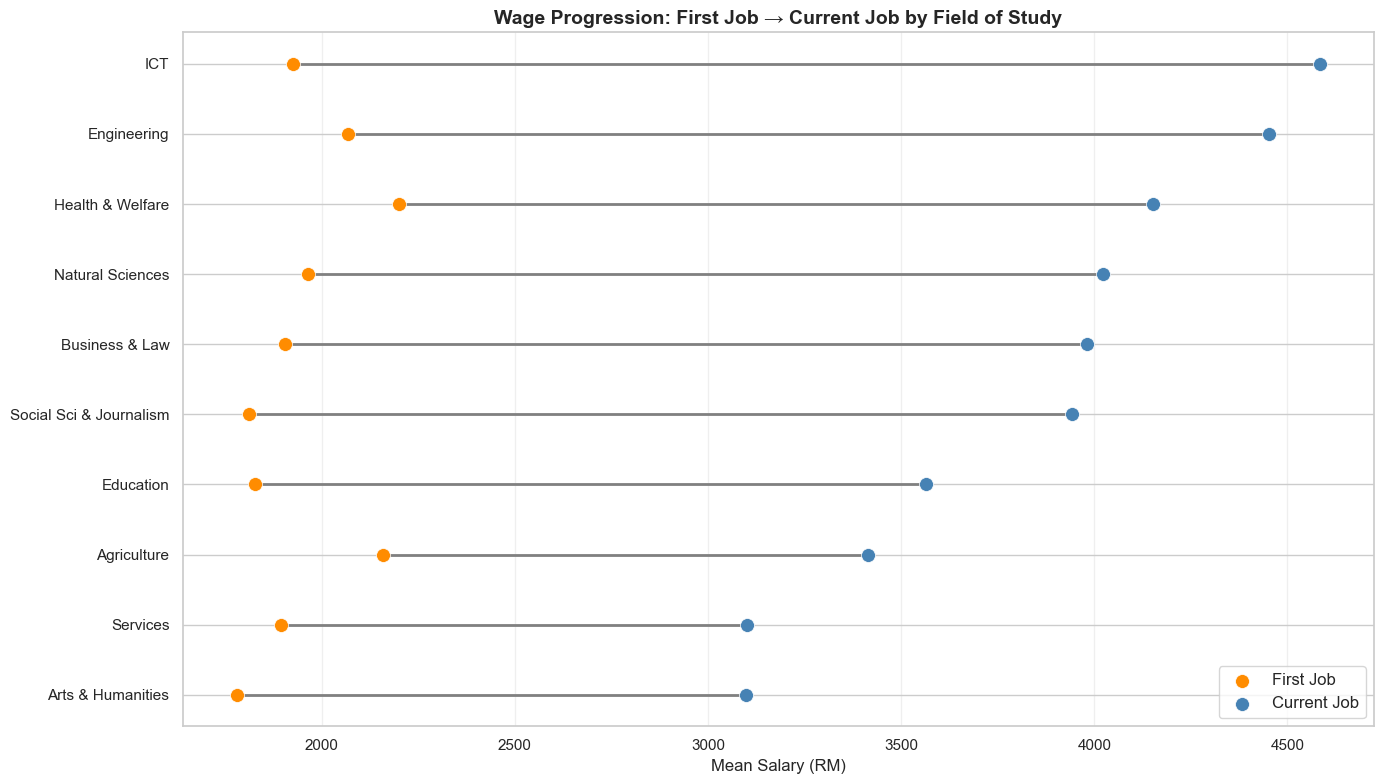

In [15]:
# --- 4d. Dumbbell / Paired Dot Plot ---

prog_means_sorted = prog_means.sort_values('salary_cj_mid')

fig, ax = plt.subplots(figsize=(14, 8))
y_pos = np.arange(len(prog_means_sorted))

# Draw connecting lines
for i, (field, row) in enumerate(prog_means_sorted.iterrows()):
    ax.plot([row['salary_fj_mid'], row['salary_cj_mid']], [i, i],
            color='gray', linewidth=2, zorder=1)

# Draw dots
ax.scatter(prog_means_sorted['salary_fj_mid'], y_pos, color='darkorange',
           s=100, zorder=2, label='First Job', edgecolors='white', linewidth=0.5)
ax.scatter(prog_means_sorted['salary_cj_mid'], y_pos, color='steelblue',
           s=100, zorder=2, label='Current Job', edgecolors='white', linewidth=0.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(prog_means_sorted.index)
ax.set_xlabel('Mean Salary (RM)', fontsize=12)
ax.set_title('Wage Progression: First Job → Current Job by Field of Study', fontsize=14, fontweight='bold')
ax.legend(fontsize=12, loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# --- 4e. Progression Summary Table ---

prog_table = df_prog.groupby('Field').agg(
    mean_first=('salary_fj_mid', 'mean'),
    mean_current=('salary_cj_mid', 'mean'),
    mean_growth_rm=('salary_progression', 'mean'),
    mean_growth_pct=('salary_growth_pct', 'mean'),
    n=('salary_progression', 'count'),
).round({'mean_first': 0, 'mean_current': 0, 'mean_growth_rm': 0, 'mean_growth_pct': 1, 'n': 0})

prog_table.columns = ['Mean First Salary (RM)', 'Mean Current Salary (RM)',
                       'Avg Growth (RM)', 'Avg Growth (%)', 'n']
prog_table = prog_table.sort_values('Avg Growth (RM)', ascending=False)
prog_table

,Mean First Salary (RM),Mean Current Salary (RM),Avg Growth (RM),Avg Growth (%),n
Field,,,,,
ICT,1925.0,4584.0,2659.0,167.6,167
Engineering,2067.0,4453.0,2386.0,143.7,511
Social Sci & Journalism,1812.0,3941.0,2129.0,142.2,128
Business & Law,1904.0,3981.0,2078.0,137.6,500
Natural Sciences,1963.0,4023.0,2060.0,138.7,259
Health & Welfare,2198.0,4153.0,1954.0,114.0,131
Education,1828.0,3564.0,1736.0,138.3,90
Arts & Humanities,1780.0,3097.0,1318.0,105.3,159
Agriculture,2158.0,3413.0,1255.0,81.8,46


---
## Section 5: Wage Progression by Cohort
Compare the ~2010 vs ~2018 graduation cohorts to see how wages differ by experience level.

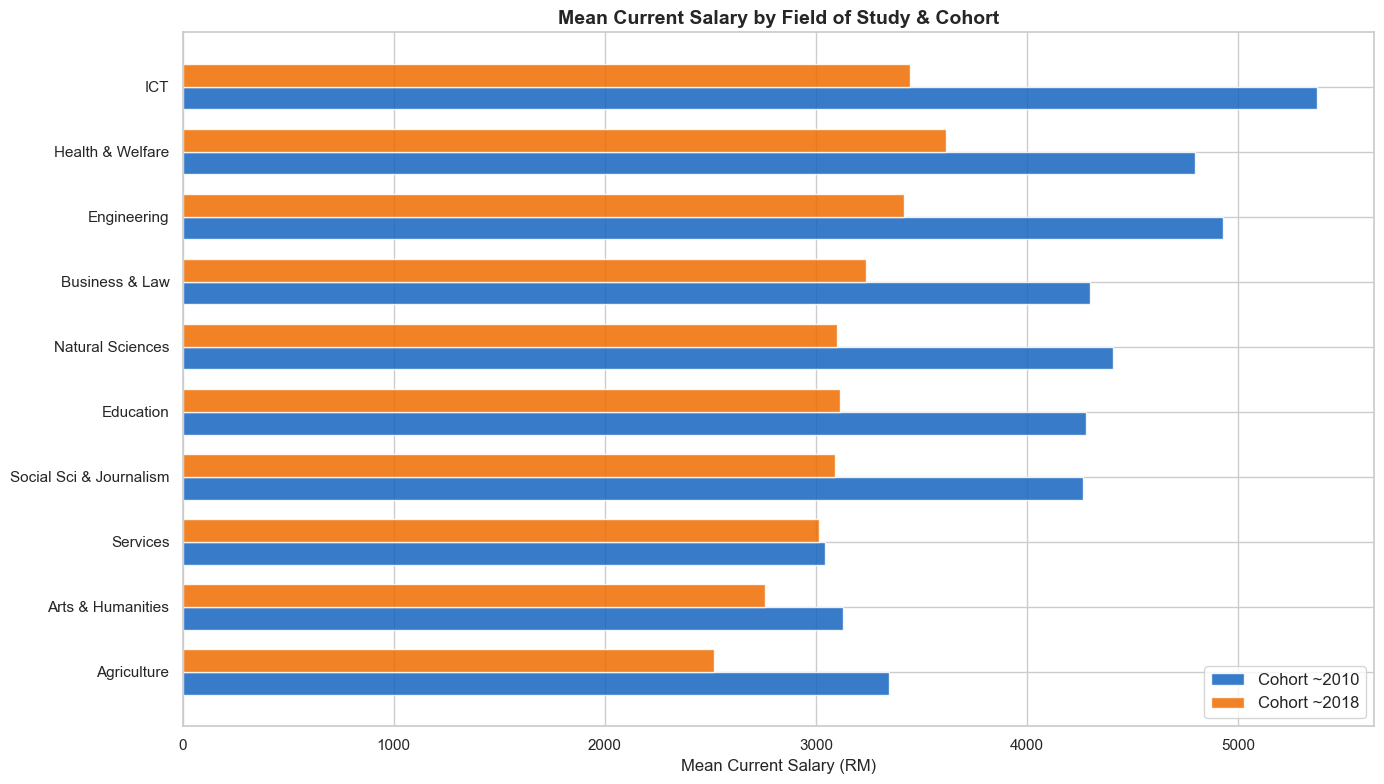

In [17]:
# --- 5a. Cohort comparison: Mean current salary by field ---

# Clean cohort labels (there's a leading space in ' ~2010')
df['cohort_clean'] = df['cohort'].str.strip()
df_prog['cohort_clean'] = df_prog['cohort'].str.strip()

cohort_field = df.dropna(subset=['salary_cj_mid']).groupby(['Field', 'cohort_clean'])['salary_cj_mid'].mean().unstack()
cohort_field = cohort_field.drop(index='General', errors='ignore')

# Sort by overall mean
cohort_field['overall'] = cohort_field.mean(axis=1)
cohort_field = cohort_field.sort_values('overall')
cohort_field = cohort_field.drop(columns='overall')

fig, ax = plt.subplots(figsize=(14, 8))
y = np.arange(len(cohort_field))
height = 0.35

if '~2010' in cohort_field.columns:
    ax.barh(y - height/2, cohort_field['~2010'], height, label='Cohort ~2010',
            color='#1565c0', edgecolor='white', alpha=0.85)
if '~2018' in cohort_field.columns:
    ax.barh(y + height/2, cohort_field['~2018'], height, label='Cohort ~2018',
            color='#ef6c00', edgecolor='white', alpha=0.85)

ax.set_yticks(y)
ax.set_yticklabels(cohort_field.index)
ax.set_xlabel('Mean Current Salary (RM)', fontsize=12)
ax.set_title('Mean Current Salary by Field of Study & Cohort', fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

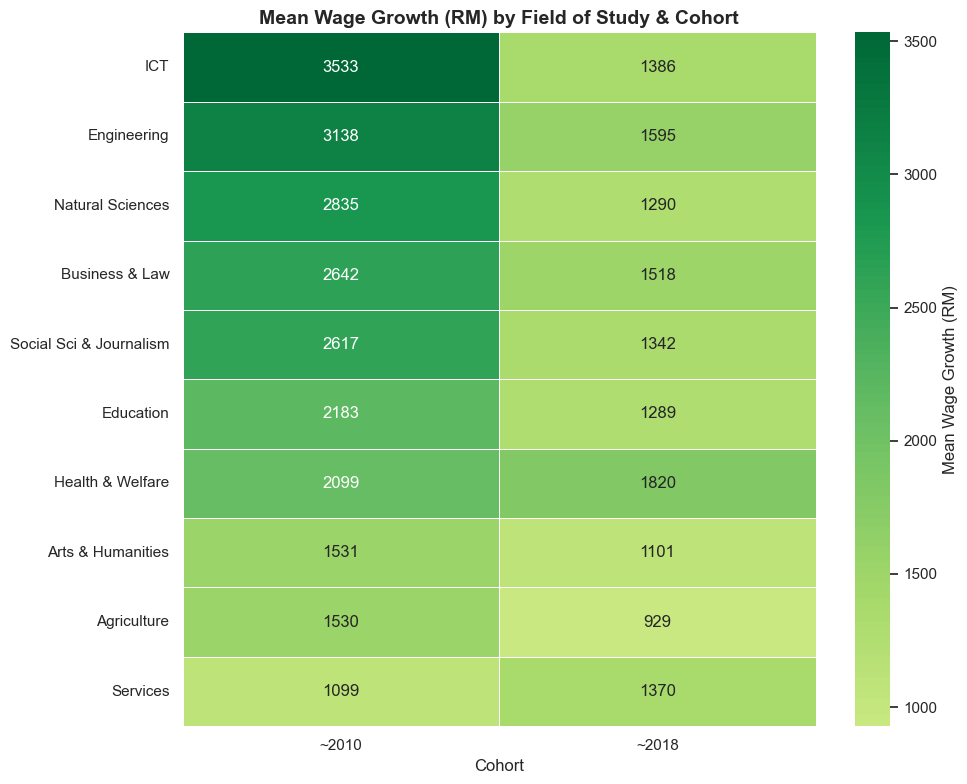

In [18]:
# --- 5b. Heatmap: Mean salary progression by Field × Cohort ---

heatmap_data = df_prog.groupby(['Field', 'cohort_clean'])['salary_progression'].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(heatmap_data.sort_values(heatmap_data.columns[0], ascending=False),
            annot=True, fmt='.0f', cmap='RdYlGn', center=0,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Mean Wage Growth (RM)'})
ax.set_title('Mean Wage Growth (RM) by Field of Study & Cohort', fontsize=14, fontweight='bold')
ax.set_ylabel('')
ax.set_xlabel('Cohort', fontsize=12)
plt.tight_layout()
plt.show()

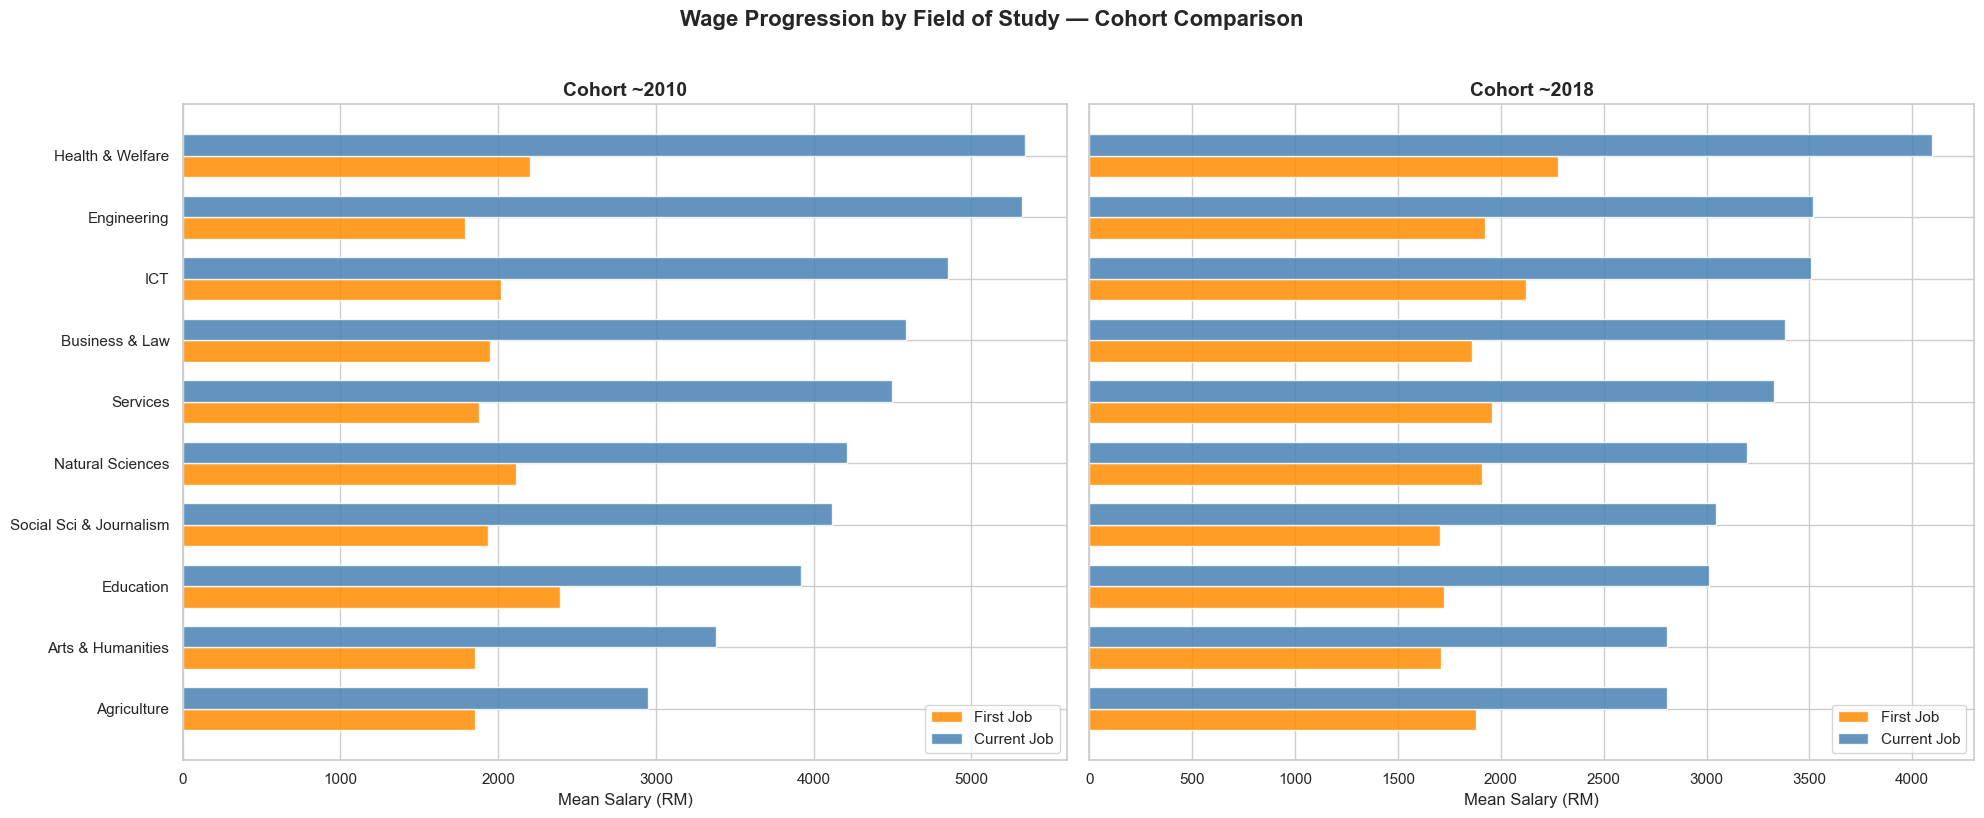

In [19]:
# --- 5c. Faceted bar chart: First → Current salary by field, per cohort ---

fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

for idx, cohort_val in enumerate(['~2010', '~2018']):
    ax = axes[idx]
    subset = df_prog[df_prog['cohort_clean'] == cohort_val]
    means = subset.groupby('Field')[['salary_fj_mid', 'salary_cj_mid']].mean().sort_values('salary_cj_mid')
    
    y = np.arange(len(means))
    height = 0.35
    ax.barh(y - height/2, means['salary_fj_mid'], height, label='First Job',
            color='darkorange', edgecolor='white', alpha=0.85)
    ax.barh(y + height/2, means['salary_cj_mid'], height, label='Current Job',
            color='steelblue', edgecolor='white', alpha=0.85)
    
    ax.set_yticks(y)
    ax.set_yticklabels(means.index)
    ax.set_xlabel('Mean Salary (RM)', fontsize=12)
    ax.set_title(f'Cohort {cohort_val}', fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)

fig.suptitle('Wage Progression by Field of Study — Cohort Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Section 6: Deeper Cuts — STEM, Education Level

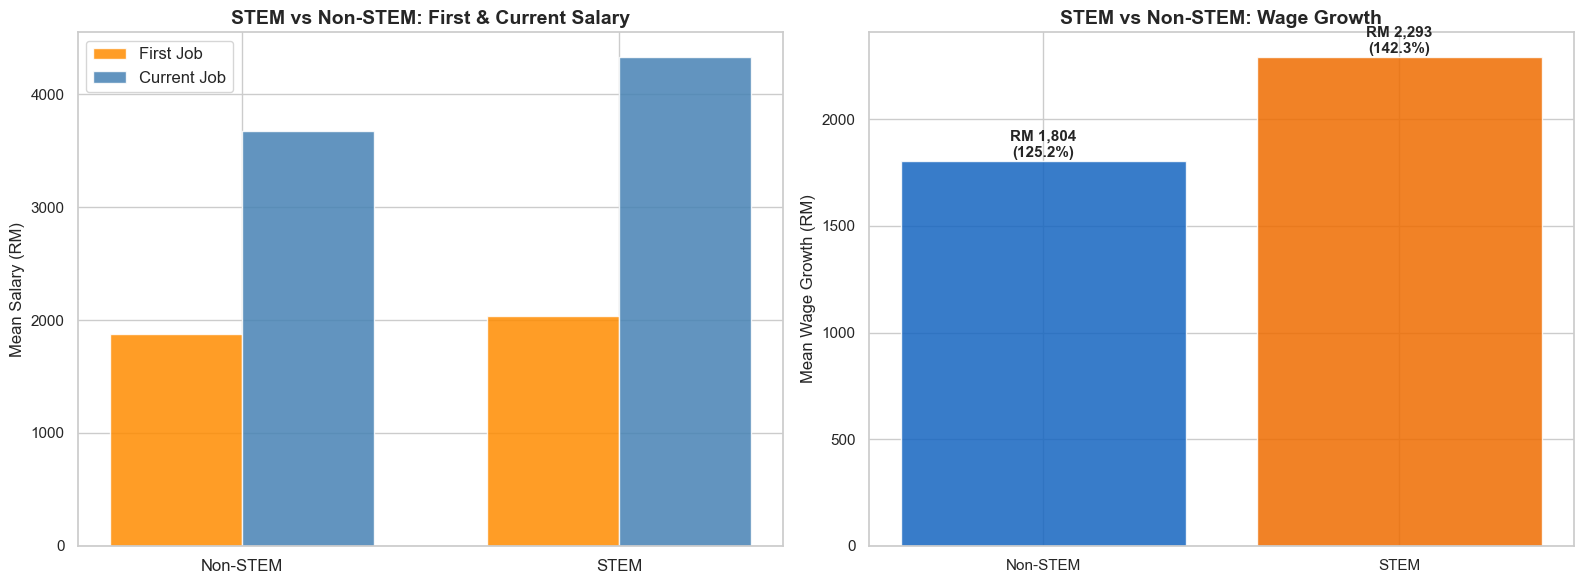


STEM vs Non-STEM Summary:


,salary_fj_mid,salary_cj_mid,salary_progression,growth_pct
STEM,,,,
Non-STEM,1874.0,3678.0,1804.0,125.0
STEM,2038.0,4332.0,2293.0,142.0


In [20]:
# --- 6a. STEM vs Non-STEM Wage Progression ---

stem_filter = df_prog[df_prog['STEM'].isin(['STEM', 'Non-STEM'])]
stem_means = stem_filter.groupby('STEM')[['salary_fj_mid', 'salary_cj_mid', 'salary_progression']].mean()
stem_means['growth_pct'] = stem_filter.groupby('STEM')['salary_growth_pct'].mean().round(1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar comparison
ax = axes[0]
x = np.arange(len(stem_means))
width = 0.35
ax.bar(x - width/2, stem_means['salary_fj_mid'], width, label='First Job', color='darkorange', alpha=0.85)
ax.bar(x + width/2, stem_means['salary_cj_mid'], width, label='Current Job', color='steelblue', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(stem_means.index, fontsize=12)
ax.set_ylabel('Mean Salary (RM)', fontsize=12)
ax.set_title('STEM vs Non-STEM: First & Current Salary', fontsize=14, fontweight='bold')
ax.legend(fontsize=12)

# Growth comparison
ax = axes[1]
colors = ['#1565c0', '#ef6c00']
bars = ax.bar(stem_means.index, stem_means['salary_progression'], color=colors, alpha=0.85, edgecolor='white')
ax.set_ylabel('Mean Wage Growth (RM)', fontsize=12)
ax.set_title('STEM vs Non-STEM: Wage Growth', fontsize=14, fontweight='bold')
for bar, val, pct in zip(bars, stem_means['salary_progression'], stem_means['growth_pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            f'RM {val:,.0f}\n({pct:.1f}%)', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print('\nSTEM vs Non-STEM Summary:')
stem_means.round(0)

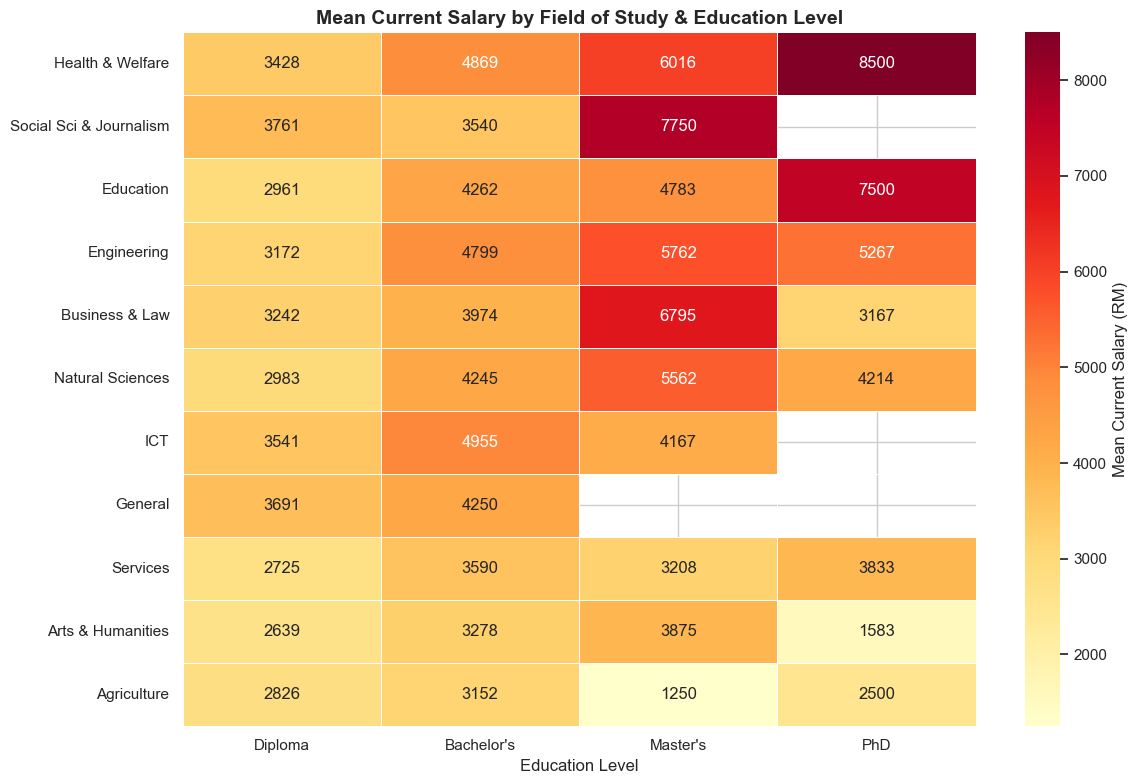

In [21]:
# --- 6b. Heatmap: Mean current salary by Education Level × Field ---

edu_field = df.dropna(subset=['salary_cj_mid']).groupby(['Field', 'max_educert'])['salary_cj_mid'].mean().unstack()

# Reorder education levels logically
edu_order = [
    'Diploma/ certificates or equivalent',
    "Bachelor's degree/ advanced diploma or equivalent",
    "Master's degree/ professional certificates or equivalent",
    'PhD or equivalent'
]
edu_short = ['Diploma', 'Bachelor\'s', 'Master\'s', 'PhD']
edu_field = edu_field[[c for c in edu_order if c in edu_field.columns]]
edu_field.columns = [edu_short[edu_order.index(c)] for c in edu_field.columns]

# Sort by overall mean
edu_field = edu_field.loc[edu_field.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(edu_field, annot=True, fmt='.0f', cmap='YlOrRd',
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Mean Current Salary (RM)'})
ax.set_title('Mean Current Salary by Field of Study & Education Level', fontsize=14, fontweight='bold')
ax.set_ylabel('')
ax.set_xlabel('Education Level', fontsize=12)
plt.tight_layout()
plt.show()

In [22]:
# --- 6c. Top & Bottom Movers ---

prog_ranked = df_prog.groupby('Field').agg(
    mean_first=('salary_fj_mid', 'mean'),
    mean_current=('salary_cj_mid', 'mean'),
    abs_growth=('salary_progression', 'mean'),
    pct_growth=('salary_growth_pct', 'mean'),
    n=('salary_progression', 'count'),
).round(0)

print('='*70)
print('TOP 5 FIELDS BY ABSOLUTE WAGE GROWTH (RM)')
print('='*70)
top5_abs = prog_ranked.sort_values('abs_growth', ascending=False).head(5)
for i, (field, row) in enumerate(top5_abs.iterrows(), 1):
    print(f"  {i}. {field}: RM {row['abs_growth']:,.0f} growth "
          f"(RM {row['mean_first']:,.0f} → RM {row['mean_current']:,.0f}), n={row['n']:.0f}")

print(f"\n{'='*70}")
print('BOTTOM 5 FIELDS BY ABSOLUTE WAGE GROWTH (RM)')
print('='*70)
bot5_abs = prog_ranked.sort_values('abs_growth', ascending=True).head(5)
for i, (field, row) in enumerate(bot5_abs.iterrows(), 1):
    print(f"  {i}. {field}: RM {row['abs_growth']:,.0f} growth "
          f"(RM {row['mean_first']:,.0f} → RM {row['mean_current']:,.0f}), n={row['n']:.0f}")

print(f"\n{'='*70}")
print('TOP 5 FIELDS BY PERCENTAGE WAGE GROWTH (%)')
print('='*70)
top5_pct = prog_ranked.sort_values('pct_growth', ascending=False).head(5)
for i, (field, row) in enumerate(top5_pct.iterrows(), 1):
    print(f"  {i}. {field}: {row['pct_growth']:.0f}% growth "
          f"(RM {row['mean_first']:,.0f} → RM {row['mean_current']:,.0f}), n={row['n']:.0f}")

TOP 5 FIELDS BY ABSOLUTE WAGE GROWTH (RM)
  1. ICT: RM 2,659 growth (RM 1,925 → RM 4,584), n=167
  2. Engineering: RM 2,386 growth (RM 2,067 → RM 4,453), n=511
  3. Social Sci & Journalism: RM 2,129 growth (RM 1,812 → RM 3,941), n=128
  4. Business & Law: RM 2,078 growth (RM 1,904 → RM 3,981), n=500
  5. Natural Sciences: RM 2,060 growth (RM 1,963 → RM 4,023), n=259

BOTTOM 5 FIELDS BY ABSOLUTE WAGE GROWTH (RM)
  1. Services: RM 1,207 growth (RM 1,895 → RM 3,101), n=121
  2. Agriculture: RM 1,255 growth (RM 2,158 → RM 3,413), n=46
  3. Arts & Humanities: RM 1,318 growth (RM 1,780 → RM 3,097), n=159
  4. Education: RM 1,736 growth (RM 1,828 → RM 3,564), n=90
  5. Health & Welfare: RM 1,954 growth (RM 2,198 → RM 4,153), n=131

TOP 5 FIELDS BY PERCENTAGE WAGE GROWTH (%)
  1. ICT: 168% growth (RM 1,925 → RM 4,584), n=167
  2. Engineering: 144% growth (RM 2,067 → RM 4,453), n=511
  3. Social Sci & Journalism: 142% growth (RM 1,812 → RM 3,941), n=128
  4. Natural Sciences: 139% growth (RM 1,

---
## Section 7: Key Findings & Takeaways

In [23]:
# --- Auto-generate key findings from the data ---

print('='*70)
print('KEY FINDINGS: WAGE PROGRESSION BY FIELD OF STUDY')
print('='*70)

# Highest / lowest current salary
cj_by_field = df.groupby('Field')['salary_cj_mid'].mean().sort_values(ascending=False)
print(f"\n📊 CURRENT SALARY RANKINGS:")
print(f"   Highest: {cj_by_field.index[0]} (RM {cj_by_field.iloc[0]:,.0f})")
print(f"   Lowest:  {cj_by_field.index[-1]} (RM {cj_by_field.iloc[-1]:,.0f})")
print(f"   Gap:     RM {cj_by_field.iloc[0] - cj_by_field.iloc[-1]:,.0f}")

# Highest / lowest first salary
fj_by_field = df.groupby('Field')['salary_fj_mid'].mean().sort_values(ascending=False)
print(f"\n📊 FIRST JOB SALARY RANKINGS:")
print(f"   Highest: {fj_by_field.index[0]} (RM {fj_by_field.iloc[0]:,.0f})")
print(f"   Lowest:  {fj_by_field.index[-1]} (RM {fj_by_field.iloc[-1]:,.0f})")
print("   Note: cross-sectional means include top-coded bands; see Section 4 caveat.")

# Greatest wage growth
growth_by_field = df_prog.groupby('Field')['salary_progression'].mean().sort_values(ascending=False)
pct_by_field = df_prog.groupby('Field')['salary_growth_pct'].mean().sort_values(ascending=False)
print(f"\n📈 WAGE GROWTH:")
print(f"   Highest absolute growth: {growth_by_field.index[0]} (+RM {growth_by_field.iloc[0]:,.0f})")
print(f"   Lowest absolute growth:  {growth_by_field.index[-1]} (+RM {growth_by_field.iloc[-1]:,.0f})")
print(f"   Highest % growth:        {pct_by_field.index[0]} (+{pct_by_field.iloc[0]:.0f}%)")
print(f"   Lowest % growth:         {pct_by_field.index[-1]} (+{pct_by_field.iloc[-1]:.0f}%)")

# STEM vs Non-STEM
stem_data = df_prog[df_prog['STEM'].isin(['STEM', 'Non-STEM'])]
stem_growth = stem_data.groupby('STEM')['salary_progression'].mean()
print(f"\n🔬 STEM vs NON-STEM:")
print(f"   STEM avg growth:     RM {stem_growth.get('STEM', 0):,.0f}")
print(f"   Non-STEM avg growth: RM {stem_growth.get('Non-STEM', 0):,.0f}")

# Cohort
cohort_growth = df_prog.groupby('cohort_clean')['salary_progression'].mean()
print(f"\n📅 COHORT COMPARISON:")
for cohort, val in cohort_growth.items():
    cj_mean = df_prog[df_prog['cohort_clean']==cohort]['salary_cj_mid'].mean()
    fj_mean = df_prog[df_prog['cohort_clean']==cohort]['salary_fj_mid'].mean()
    print(f"   {cohort}: First RM {fj_mean:,.0f} → Current RM {cj_mean:,.0f} (growth RM {val:,.0f})")

print(f"\n{'='*70}")

KEY FINDINGS: WAGE PROGRESSION BY FIELD OF STUDY

📊 CURRENT SALARY RANKINGS:
   Highest: ICT (RM 4,395)
   Lowest:  Arts & Humanities (RM 2,939)
   Gap:     RM 1,456

📊 FIRST JOB SALARY RANKINGS:
   Highest: Services (RM 2,673)
   Lowest:  Arts & Humanities (RM 1,797)
   Note: cross-sectional means include top-coded bands; see Section 4 caveat.

📈 WAGE GROWTH:
   Highest absolute growth: ICT (+RM 2,659)
   Lowest absolute growth:  Services (+RM 1,207)
   Highest % growth:        ICT (+168%)
   Lowest % growth:         Agriculture (+82%)

🔬 STEM vs NON-STEM:
   STEM avg growth:     RM 2,293
   Non-STEM avg growth: RM 1,804

📅 COHORT COMPARISON:
   ~2010: First RM 2,003 → Current RM 4,606 (growth RM 2,603)
   ~2018: First RM 1,907 → Current RM 3,356 (growth RM 1,448)

